# 16 — RAID adversarial attack response

Goal: characterize which RAID attacks change our completed-text measurements.

For clean text \(x\) and attacked text \(A(x)\), analyze paired changes in:
- \(L_{256}\)
- compressed geometric context probing \(G=(L_8,L_{16},L_{32},L_{64},L_{128},L_{256})\)
- recurrence frontloading \(F\)
- any cached topology features \(T_{256,*}\)

This is an invariance/sensitivity experiment, not an attack detector.


In [1]:
import sys
import subprocess

# Restore the versions your research environment was using before raid-bench
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--upgrade",
    "numpy==2.5.2",
    "pandas==3.0.5",
    "scipy==1.18.0",
    "scikit-learn==1.9.0",
])

0

In [2]:
import sys
import subprocess

# Restore the versions your research environment was using before raid-bench
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--upgrade",
    "numpy==2.5.2",
    "pandas==3.0.5",
    "scipy==1.18.0",
    "scikit-learn==1.9.0",
])

0

In [3]:
import numpy as np
import pandas as pd
import scipy
import sklearn

print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scipy:", scipy.__version__)
print("sklearn:", sklearn.__version__)

numpy: 2.5.2
pandas: 3.0.5
scipy: 1.18.0
sklearn: 1.9.0


In [4]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--no-deps",
    "raid-bench",
])

0

In [5]:
from pathlib import Path

RAID_CSV = Path.home() / ".cache" / "raid" / "train.csv"
print(RAID_CSV)
print("exists:", RAID_CSV.exists())
print("GB:", RAID_CSV.stat().st_size / 1e9)

/home/user/.cache/raid/train.csv
exists: True
GB: 11.779491051


In [6]:
import pandas as pd

preview = pd.read_csv(
    RAID_CSV,
    nrows=5,
)

print(preview.columns.tolist())
display(preview)

['id', 'adv_source_id', 'source_id', 'model', 'decoding', 'repetition_penalty', 'attack', 'domain', 'title', 'prompt', 'generation']


,id,adv_source_id,source_id,model,decoding,repetition_penalty,attack,domain,title,prompt,generation
0,e5e058ce-be2b-459d-af36-32532aaba5ff,e5e058ce-be2b-459d-af36-32532aaba5ff,e5e058ce-be2b-459d-af36-32532aaba5ff,human,NaN,NaN,none,abstracts,FUTURE-AI: Guiding Principles and Consensus Re...,NaN,The recent advancements in artificial intellig...
1,f95b107b-d176-4af5-90f7-4d0bb20caf93,f95b107b-d176-4af5-90f7-4d0bb20caf93,f95b107b-d176-4af5-90f7-4d0bb20caf93,human,NaN,NaN,none,abstracts,EdgeFlow: Achieving Practical Interactive Segm...,NaN,High-quality training data play a key role in ...
2,856d8972-9e3d-4544-babc-0fe16f21e04d,856d8972-9e3d-4544-babc-0fe16f21e04d,856d8972-9e3d-4544-babc-0fe16f21e04d,human,NaN,NaN,none,abstracts,Semi-supervised Contrastive Learning for Label...,NaN,The success of deep learning methods in medica...
3,fbc8a5ea-90fa-47b8-8fa7-73dd954f1524,fbc8a5ea-90fa-47b8-8fa7-73dd954f1524,fbc8a5ea-90fa-47b8-8fa7-73dd954f1524,human,NaN,NaN,none,abstracts,Combo Loss: Handling Input and Output Imbalanc...,NaN,Simultaneous segmentation of multiple organs f...
4,72c41b8d-0069-4886-b734-a4000ffca286,72c41b8d-0069-4886-b734-a4000ffca286,72c41b8d-0069-4886-b734-a4000ffca286,human,NaN,NaN,none,abstracts,Attention-Based 3D Seismic Fault Segmentation ...,NaN,Detection faults in seismic data is a crucial ...


In [7]:
from collections import Counter

attack_counts = Counter()
model_counts = Counter()
domain_counts = Counter()

USECOLS = [
    "attack",
    "model",
    "domain",
]

for chunk in pd.read_csv(
    RAID_CSV,
    usecols=USECOLS,
    chunksize=100_000,
):
    attack_counts.update(chunk["attack"].astype(str))
    model_counts.update(chunk["model"].astype(str))
    domain_counts.update(chunk["domain"].astype(str))

print("ATTACKS")
display(
    pd.DataFrame(
        attack_counts.items(),
        columns=["attack", "n"],
    ).sort_values("n", ascending=False)
)

print("MODELS")
display(
    pd.DataFrame(
        model_counts.items(),
        columns=["model", "n"],
    ).sort_values("n", ascending=False)
)

print("DOMAINS")
display(
    pd.DataFrame(
        domain_counts.items(),
        columns=["domain", "n"],
    ).sort_values("n", ascending=False)
)

ATTACKS


,attack,n
0,none,467985
1,whitespace,467985
2,upper_lower,467985
3,synonym,467985
4,perplexity_misspelling,467985
5,paraphrase,467985
6,number,467985
7,insert_paragraphs,467985
8,homoglyph,467985
9,article_deletion,467985


MODELS


,model,n
1,llama-chat,641808
2,mpt,641808
3,mpt-chat,641808
4,gpt2,641808
6,mistral-chat,641808
5,mistral,641808
8,cohere,320904
7,gpt3,320904
10,gpt4,320904
9,chatgpt,320904


DOMAINS


,domain,n
1,books,748020
2,news,747600
7,wiki,747180
5,reddit,747180
4,recipes,744240
3,poetry,743820
0,abstracts,741720
6,reviews,396060


In [8]:
import pandas as pd
from collections import defaultdict

USECOLS = [
    "id",
    "adv_source_id",
    "source_id",
    "model",
    "decoding",
    "repetition_penalty",
    "attack",
    "domain",
    "generation",
]

MAX_PER_ATTACK = 50

selected_attacks = defaultdict(list)
clean_by_id = {}

for chunk in pd.read_csv(
    RAID_CSV,
    usecols=USECOLS,
    chunksize=50_000,
):
    # Restrict immediately to news.
    chunk = chunk[chunk["domain"] == "news"].copy()

    # Store clean generations by id.
    clean_chunk = chunk[chunk["attack"] == "none"]

    for row in clean_chunk.itertuples(index=False):
        clean_by_id[row.id] = row._asdict()

    # Collect a capped number of attacked examples.
    attack_chunk = chunk[chunk["attack"] != "none"]

    for attack, g in attack_chunk.groupby("attack"):
        remaining = MAX_PER_ATTACK - len(selected_attacks[attack])

        if remaining <= 0:
            continue

        selected_attacks[attack].extend(
            g.head(remaining).to_dict("records")
        )

attacked_small = pd.DataFrame([
    row
    for rows in selected_attacks.values()
    for row in rows
])

print(attacked_small["attack"].value_counts())
print("attacked rows:", len(attacked_small))

attack
upper_lower               50
whitespace                50
perplexity_misspelling    50
synonym                   50
number                    50
paraphrase                50
article_deletion          50
homoglyph                 50
insert_paragraphs         50
alternative_spelling      50
zero_width_space          50
Name: count, dtype: int64
attacked rows: 550


In [9]:
needed_clean_ids = set(attacked_small["adv_source_id"])

clean_small = pd.DataFrame([
    clean_by_id[x]
    for x in needed_clean_ids
    if x in clean_by_id
])

print("clean parents found:", len(clean_small))
print("needed:", len(needed_clean_ids))

clean parents found: 50
needed: 50


In [10]:
print("unique attacked source ids:", attacked_small["adv_source_id"].nunique())

coverage = (
    attacked_small.groupby("adv_source_id")["attack"]
    .nunique()
)

print("\nATTACKS PER SOURCE")
display(coverage.describe())

print("\nSOURCE × ATTACK COVERAGE")
coverage_table = pd.crosstab(
    attacked_small["adv_source_id"],
    attacked_small["attack"],
)

display(coverage_table)

print("\nAll sources have all 11 attacks:",
      bool((coverage_table == 1).all().all()))

unique attacked source ids: 50

ATTACKS PER SOURCE


count    50.0
mean     11.0
std       0.0
min      11.0
25%      11.0
50%      11.0
75%      11.0
max      11.0
Name: attack, dtype: float64


SOURCE × ATTACK COVERAGE


attack,alternative_spelling,article_deletion,homoglyph,insert_paragraphs,number,paraphrase,perplexity_misspelling,synonym,upper_lower,whitespace,zero_width_space
adv_source_id,,,,,,,,,,,
04ff6b83-9aec-498f-9304-500f061a1f46,1,1,1,1,1,1,1,1,1,1,1
088f015c-f1f5-47a1-843c-a597f7dfd1bc,1,1,1,1,1,1,1,1,1,1,1
0e34d9dc-0f4d-4056-b16e-dfb4f1261b29,1,1,1,1,1,1,1,1,1,1,1
0e9df493-693f-4f59-abda-448f7a50724e,1,1,1,1,1,1,1,1,1,1,1
140bcdd4-cb85-49b7-ad40-483a21380193,1,1,1,1,1,1,1,1,1,1,1
1d287242-1303-43a4-96c6-5056157f8c88,1,1,1,1,1,1,1,1,1,1,1
2a61ecf0-a0f1-485c-b959-5fbf52a436da,1,1,1,1,1,1,1,1,1,1,1
2b2b5286-a1b7-4c1c-8bd2-229bdd1db554,1,1,1,1,1,1,1,1,1,1,1
301a0027-7377-4b6e-85c1-48cfc8d2badb,1,1,1,1,1,1,1,1,1,1,1



All sources have all 11 attacks: True


In [11]:
clean_small = clean_small.copy()
clean_small["variant"] = "clean"
clean_small["parent_id"] = clean_small["id"]

attacked_small = attacked_small.copy()
attacked_small["variant"] = attacked_small["attack"]
attacked_small["parent_id"] = attacked_small["adv_source_id"]

score_df = pd.concat(
    [
        clean_small,
        attacked_small,
    ],
    ignore_index=True,
)

score_df = score_df.drop_duplicates("id").copy()

print("documents to score:", len(score_df))
print("clean:", (score_df["variant"] == "clean").sum())
print("attacked:", (score_df["variant"] != "clean").sum())

display(score_df["variant"].value_counts())

documents to score: 600
clean: 50
attacked: 550


variant
clean                     50
upper_lower               50
whitespace                50
perplexity_misspelling    50
synonym                   50
number                    50
paraphrase                50
article_deletion          50
homoglyph                 50
insert_paragraphs         50
alternative_spelling      50
zero_width_space          50
Name: count, dtype: int64

In [12]:
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen3-0.6B-Base"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
)

model.eval()
model.to(DEVICE)

K_VALUES = [8, 16, 32, 64, 128, 256]

TARGETS = np.linspace(
    256,
    383,
    8,
).round().astype(int)

print("targets:", TARGETS)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 1056.98it/s]


targets: [256 274 292 310 329 347 365 383]


In [20]:
@torch.inference_mode()
def nll_at_context(ids, target, k):
    """
    NLL of token ids[target] using exactly the preceding k tokens.
    """
    start = max(0, target - k)

    # Include target token so causal LM prediction at final-1
    # predicts ids[target].
    x = torch.tensor(
        ids[start:target + 1],
        dtype=torch.long,
        device=DEVICE,
    )[None, :]

    logits = model(input_ids=x).logits

    pred = logits[0, -2]
    target_id = torch.tensor(
        ids[target],
        device=DEVICE,
    )

    return float(
        torch.nn.functional.cross_entropy(
            pred.float()[None, :],
            target_id[None],
        ).item()
    )


def score_document(text):
    ids = tokenizer(
        text,
        add_special_tokens=False,
        truncation=True,
        max_length=384,
    )["input_ids"]

    if len(ids) <= 256:
        return None

    last_target = len(ids) - 1

    targets = np.linspace(
        256,
        last_target,
        min(8, last_target - 255),
    ).round().astype(int)

    targets = np.unique(targets)

    result = {
        "n_tokens_scored": len(ids),
        "n_targets": len(targets),
    }

    for k in K_VALUES:
        vals = [
            nll_at_context(ids, int(t), k)
            for t in targets
        ]

        result[f"L_{k}"] = float(np.mean(vals))

    return result

In [15]:
from pathlib import Path

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RESULTS:", RESULTS)

ROOT: ..
RESULTS: ../results


In [18]:
from pathlib import Path
from collections import defaultdict
import pandas as pd
import numpy as np

RAID_CSV = Path.home() / ".cache" / "raid" / "train.csv"

MACHINE_MODELS = [
    "gpt2",
    "mpt",
    "mpt-chat",
    "mistral",
    "mistral-chat",
    "llama-chat",
    "cohere",
    "cohere-chat",
    "gpt3",
    "gpt4",
    "chatgpt",
]

ATTACKS = [
    "alternative_spelling",
    "article_deletion",
    "homoglyph",
    "insert_paragraphs",
    "number",
    "paraphrase",
    "perplexity_misspelling",
    "synonym",
    "upper_lower",
    "whitespace",
    "zero_width_space",
]

USECOLS = [
    "id",
    "adv_source_id",
    "source_id",
    "model",
    "decoding",
    "repetition_penalty",
    "attack",
    "domain",
    "generation",
]

# source -> set of attacks observed
attack_sets = defaultdict(set)
source_model = {}

for chunk in pd.read_csv(
    RAID_CSV,
    usecols=USECOLS,
    chunksize=100_000,
):
    chunk = chunk[
        (chunk["domain"] == "news")
        & (chunk["model"].isin(MACHINE_MODELS))
    ]

    attacked = chunk[chunk["attack"] != "none"]

    for adv_id, g in attacked.groupby("adv_source_id"):
        attack_sets[adv_id].update(g["attack"].astype(str))
        source_model[adv_id] = g["model"].iloc[0]

complete_ids = [
    sid
    for sid, attacks in attack_sets.items()
    if set(ATTACKS).issubset(attacks)
]

print("complete machine panels:", len(complete_ids))

complete_by_model = defaultdict(list)

for sid in complete_ids:
    complete_by_model[source_model[sid]].append(sid)

for model in sorted(complete_by_model):
    print(model, len(complete_by_model[model]))

complete machine panels: 60520
chatgpt 3560
cohere 3560
cohere-chat 3560
gpt2 7120
gpt3 3560
gpt4 3560
llama-chat 7120
mistral 7120
mistral-chat 7120
mpt 7120
mpt-chat 7120


In [19]:
rng = np.random.default_rng(1601)

selected_ids = []

for model in sorted(complete_by_model):
    ids = np.array(sorted(complete_by_model[model]))

    # Aim for 5 per model.
    n = min(5, len(ids))

    chosen = rng.choice(
        ids,
        size=n,
        replace=False,
    )

    selected_ids.extend(chosen.tolist())

print("selected sources:", len(selected_ids))

print(
    pd.Series(
        [source_model[x] for x in selected_ids]
    ).value_counts()
)

selected sources: 55
chatgpt         5
cohere          5
cohere-chat     5
gpt2            5
gpt3            5
gpt4            5
llama-chat      5
mistral         5
mistral-chat    5
mpt             5
mpt-chat        5
Name: count, dtype: int64


In [22]:
selected_ids = set(selected_ids)

USECOLS = [
    "id",
    "adv_source_id",
    "source_id",
    "model",
    "decoding",
    "repetition_penalty",
    "attack",
    "domain",
    "generation",
]

rows = []

for chunk in pd.read_csv(
    RAID_CSV,
    usecols=USECOLS,
    chunksize=100_000,
):
    clean_mask = (
        chunk["id"].isin(selected_ids)
        & (chunk["attack"] == "none")
    )

    attack_mask = (
        chunk["adv_source_id"].isin(selected_ids)
        & (chunk["attack"] != "none")
    )

    keep = chunk[clean_mask | attack_mask]

    if len(keep):
        rows.append(keep)

machine_panel = pd.concat(rows, ignore_index=True)

print("rows:", len(machine_panel))
print("clean:", (machine_panel["attack"] == "none").sum())
print("attacked:", (machine_panel["attack"] != "none").sum())
print("sources:", machine_panel["adv_source_id"].nunique())

print("\nMODEL COUNTS")
display(
    machine_panel.groupby(["model", "attack"])
    .size()
    .unstack(fill_value=0)
)

print("\nROWS PER SOURCE")
display(
    machine_panel.groupby("adv_source_id")
    .size()
    .describe()
)

rows: 660
clean: 55
attacked: 605
sources: 55

MODEL COUNTS


attack,alternative_spelling,article_deletion,homoglyph,insert_paragraphs,none,number,paraphrase,perplexity_misspelling,synonym,upper_lower,whitespace,zero_width_space
model,,,,,,,,,,,,
chatgpt,5,5,5,5,5,5,5,5,5,5,5,5
cohere,5,5,5,5,5,5,5,5,5,5,5,5
cohere-chat,5,5,5,5,5,5,5,5,5,5,5,5
gpt2,5,5,5,5,5,5,5,5,5,5,5,5
gpt3,5,5,5,5,5,5,5,5,5,5,5,5
gpt4,5,5,5,5,5,5,5,5,5,5,5,5
llama-chat,5,5,5,5,5,5,5,5,5,5,5,5
mistral,5,5,5,5,5,5,5,5,5,5,5,5
mistral-chat,5,5,5,5,5,5,5,5,5,5,5,5



ROWS PER SOURCE


count    55.0
mean     12.0
std       0.0
min      12.0
25%      12.0
50%      12.0
75%      12.0
max      12.0
dtype: float64

In [23]:
machine_panel = machine_panel.copy()

machine_panel["variant"] = machine_panel["attack"]

machine_panel["parent_id"] = np.where(
    machine_panel["attack"] == "none",
    machine_panel["id"],
    machine_panel["adv_source_id"],
)

score_df = machine_panel.copy()

print("documents to score:", len(score_df))
display(score_df["variant"].value_counts())

documents to score: 660


variant
none                      55
whitespace                55
upper_lower               55
synonym                   55
perplexity_misspelling    55
paraphrase                55
number                    55
insert_paragraphs         55
homoglyph                 55
article_deletion          55
alternative_spelling      55
zero_width_space          55
Name: count, dtype: int64

In [25]:
CACHE = RESULTS / "raid_attacks_machine_sl6_qwen06b.parquet"

@torch.inference_mode()
def score_document(text):
    ids = tokenizer(
        text,
        add_special_tokens=False,
        truncation=True,
        max_length=384,
    )["input_ids"]

    if len(ids) <= 256:
        return None

    last_target = len(ids) - 1

    targets = np.linspace(
        256,
        last_target,
        min(8, last_target - 255),
    ).round().astype(int)

    targets = np.unique(targets)

    result = {
        "n_tokens_scored": len(ids),
        "n_targets": len(targets),
    }

    for k in K_VALUES:
        vals = [
            nll_at_context(ids, int(t), k)
            for t in targets
        ]
        result[f"L_{k}"] = float(np.mean(vals))

    return result

## Load RAID table

If the automatic choice is wrong, set `RAID_PATH` manually.


In [26]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

assert "machine_panel" in globals(), "Run the completed first half first."

machine_panel = machine_panel.copy()
machine_panel["variant"] = machine_panel["attack"].astype(str)
machine_panel["parent_id"] = np.where(
    machine_panel["attack"].eq("none"),
    machine_panel["id"],
    machine_panel["adv_source_id"],
)
score_df = machine_panel.drop_duplicates("id").copy()

assert len(score_df) == 660
assert score_df["attack"].eq("none").sum() == 55
assert score_df["parent_id"].nunique() == 55

print("documents:", len(score_df))
print("clean:", int(score_df["attack"].eq("none").sum()))
print("attacked:", int((~score_df["attack"].eq("none")).sum()))


documents: 660
clean: 55
attacked: 605


In [27]:
MODEL_ID = "Qwen/Qwen3-0.6B-Base"
K_VALUES = [8,16,32,64,128,256]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE)
model.eval().to(DEVICE)

@torch.inference_mode()
def nll_at_context(ids, target, k):
    start = max(0, target-k)
    x = torch.tensor(ids[start:target+1], dtype=torch.long, device=DEVICE)[None,:]
    logits = model(input_ids=x).logits
    pred = logits[0,-2].float()
    target_id = torch.tensor([ids[target]], dtype=torch.long, device=DEVICE)
    return float(torch.nn.functional.cross_entropy(pred[None,:], target_id).item())

def score_document(text):
    ids = tokenizer(
        str(text),
        add_special_tokens=False,
        truncation=True,
        max_length=384,
    )["input_ids"]

    if len(ids) <= 256:
        return None

    last_target = len(ids)-1
    targets = np.unique(
        np.linspace(
            256,
            last_target,
            min(8, last_target-255),
        ).round().astype(int)
    )

    out = {"n_tokens_scored":len(ids), "n_targets":len(targets)}
    for k in K_VALUES:
        out[f"L_{k}"] = float(np.mean([
            nll_at_context(ids, int(t), k) for t in targets
        ]))
    return out

CACHE = RESULTS / "raid_attacks_machine_sl6_qwen06b.parquet"
scored = pd.read_parquet(CACHE) if CACHE.exists() else pd.DataFrame()
done = set(scored["id"]) if len(scored) else set()
pending = []
t0 = time.time()

for i,r in enumerate(score_df.itertuples(index=False), start=1):
    if r.id in done:
        continue

    s = score_document(r.generation)
    row = {
        "id":r.id,
        "parent_id":r.parent_id,
        "variant":r.variant,
        "attack":r.attack,
        "adv_source_id":r.adv_source_id,
        "source_id":r.source_id,
        "model":r.model,
        "domain":r.domain,
    }

    if s is None:
        row.update({
            "n_tokens_scored":np.nan,
            "n_targets":np.nan,
            **{f"L_{k}":np.nan for k in K_VALUES},
        })
    else:
        row.update(s)

    pending.append(row)

    if len(pending) >= 10 or i == len(score_df):
        scored = pd.concat([scored,pd.DataFrame(pending)], ignore_index=True)
        scored = scored.drop_duplicates("id", keep="last")
        scored.to_parquet(CACHE, index=False)
        done = set(scored["id"])
        pending = []
        print(
            f"{i}/{len(score_df)} visited | "
            f"{len(done)} cached | "
            f"{(time.time()-t0)/60:.1f} min"
        )

print("cache:", CACHE)


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 2528.29it/s]


10/660 visited | 10 cached | 0.1 min
20/660 visited | 20 cached | 0.3 min
30/660 visited | 30 cached | 0.4 min
40/660 visited | 40 cached | 0.5 min
50/660 visited | 50 cached | 0.7 min
60/660 visited | 60 cached | 0.8 min
70/660 visited | 70 cached | 0.9 min
80/660 visited | 80 cached | 1.1 min
90/660 visited | 90 cached | 1.2 min
100/660 visited | 100 cached | 1.3 min
110/660 visited | 110 cached | 1.4 min
120/660 visited | 120 cached | 1.5 min
130/660 visited | 130 cached | 1.7 min
140/660 visited | 140 cached | 1.8 min
150/660 visited | 150 cached | 1.9 min
160/660 visited | 160 cached | 2.1 min
170/660 visited | 170 cached | 2.2 min
180/660 visited | 180 cached | 2.3 min
190/660 visited | 190 cached | 2.4 min
200/660 visited | 200 cached | 2.5 min
210/660 visited | 210 cached | 2.7 min
220/660 visited | 220 cached | 2.8 min
230/660 visited | 230 cached | 2.9 min
240/660 visited | 240 cached | 3.1 min
250/660 visited | 250 cached | 3.2 min
260/660 visited | 260 cached | 3.3 min
270/

In [28]:
L_COLS = [f"L_{k}" for k in K_VALUES]

clean = scored[scored["attack"].eq("none")].copy()
attacked = scored[~scored["attack"].eq("none")].copy()

clean_ref = clean[["id","model"]+L_COLS].rename(columns={
    "id":"parent_id",
    "model":"parent_model",
    **{c:f"{c}_clean" for c in L_COLS},
})

paired_all = attacked.merge(
    clean_ref,
    on="parent_id",
    how="inner",
    validate="many_to_one",
)

for c in L_COLS:
    paired_all[f"d_{c}"] = paired_all[c] - paired_all[f"{c}_clean"]

need = L_COLS + [f"{c}_clean" for c in L_COLS]
pair_valid = paired_all[paired_all[need].notna().all(axis=1)].copy()

counts = pair_valid.groupby("parent_id")["attack"].nunique()
complete_parent_ids = set(counts[counts==11].index)
paired = pair_valid[pair_valid["parent_id"].isin(complete_parent_ids)].copy()

print("eligible clean:", clean[L_COLS].notna().all(axis=1).sum(), "/", len(clean))
print("eligible attack pairs:", len(pair_valid), "/", len(attacked))
print("complete parents:", len(complete_parent_ids))
print("primary paired rows:", len(paired))
display(pd.crosstab(paired["parent_model"], paired["attack"]))


eligible clean: 38 / 55
eligible attack pairs: 411 / 605
complete parents: 33
primary paired rows: 363


attack,alternative_spelling,article_deletion,homoglyph,insert_paragraphs,number,paraphrase,perplexity_misspelling,synonym,upper_lower,whitespace,zero_width_space
parent_model,,,,,,,,,,,
chatgpt,5,5,5,5,5,5,5,5,5,5,5
cohere,2,2,2,2,2,2,2,2,2,2,2
cohere-chat,3,3,3,3,3,3,3,3,3,3,3
gpt2,4,4,4,4,4,4,4,4,4,4,4
gpt3,1,1,1,1,1,1,1,1,1,1,1
gpt4,5,5,5,5,5,5,5,5,5,5,5
llama-chat,5,5,5,5,5,5,5,5,5,5,5
mistral,3,3,3,3,3,3,3,3,3,3,3
mistral-chat,3,3,3,3,3,3,3,3,3,3,3


In [29]:
def boot_ci(x, n_boot=10000, seed=1601):
    x = np.asarray(x,float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0,len(x),size=(n_boot,len(x)))
    return np.quantile(x[idx].mean(axis=1),[.025,.975])

clean_primary = clean[clean["id"].isin(complete_parent_ids)].copy()
clean_sd = {c:clean_primary[c].std(ddof=1) for c in L_COLS}

rows = []
for attack,g in paired.groupby("attack"):
    for c in L_COLS:
        d = g[f"d_{c}"].to_numpy(float)
        lo,hi = boot_ci(d)
        sd = d.std(ddof=1)
        rows.append({
            "attack":attack,
            "feature":c,
            "n":len(d),
            "mean_delta":d.mean(),
            "median_delta":np.median(d),
            "ci95_lo":lo,
            "ci95_hi":hi,
            "paired_dz":d.mean()/sd if sd>0 else np.nan,
            "mean_abs_delta":np.abs(d).mean(),
            "normalized_sensitivity":np.abs(d).mean()/clean_sd[c],
        })

summary = pd.DataFrame(rows)

sd_vec = np.array([clean_sd[c] for c in L_COLS],float)
D = paired[[f"d_{c}" for c in L_COLS]].to_numpy(float)/sd_vec[None,:]
paired["sl6_displacement"] = np.sqrt(np.sum(D**2,axis=1))

sl6 = (
    paired.groupby("attack")["sl6_displacement"]
    .agg(["count","mean","median","std"])
    .sort_values("mean",ascending=False)
)

summary.to_csv(RESULTS/"raid_machine_attack_context_summary.csv",index=False)
sl6.to_csv(RESULTS/"raid_machine_attack_sl6_displacement.csv")

print("L256:")
display(
    summary[summary["feature"].eq("L_256")]
    .sort_values("normalized_sensitivity",ascending=False)
)

print("\nSL6 displacement:")
display(sl6)


L256:


,attack,feature,n,mean_delta,median_delta,ci95_lo,ci95_hi,paired_dz,mean_abs_delta,normalized_sensitivity
47,synonym,L_256,33,0.923375,1.004177,0.501436,1.382435,0.714777,1.165331,0.972099
65,zero_width_space,L_256,33,-0.805062,-0.629127,-1.260369,-0.358925,-0.599309,1.119513,0.933879
17,homoglyph,L_256,33,0.675230,0.627187,0.273331,1.105912,0.548515,1.095586,0.913919
41,perplexity_misspelling,L_256,33,0.548521,0.133706,0.089287,1.080077,0.368843,1.007219,0.840205
59,whitespace,L_256,33,0.304090,0.290633,0.000382,0.621733,0.322857,0.779066,0.649884
53,upper_lower,L_256,33,0.368202,0.240587,0.054039,0.684152,0.392604,0.723418,0.603463
11,article_deletion,L_256,33,0.260684,0.128313,-0.049986,0.580716,0.277224,0.713488,0.595180
35,paraphrase,L_256,33,0.183815,0.118166,-0.108465,0.475116,0.213569,0.663560,0.553530
23,insert_paragraphs,L_256,33,0.219187,0.152325,-0.043822,0.490458,0.275971,0.630454,0.525914
5,alternative_spelling,L_256,33,0.175162,0.000000,0.017266,0.351235,0.352321,0.279614,0.233249



SL6 displacement:


,count,mean,median,std
attack,,,,
homoglyph,33,2.878859,2.829949,1.661082
zero_width_space,33,2.756745,2.311913,2.010957
synonym,33,2.632765,2.454744,1.675299
perplexity_misspelling,33,2.254985,1.826469,2.095833
whitespace,33,2.130692,1.904620,1.124620
upper_lower,33,1.956852,1.571851,1.545091
paraphrase,33,1.850277,1.537413,1.195542
article_deletion,33,1.833570,1.677397,1.199815
insert_paragraphs,33,1.623490,1.298767,1.001849


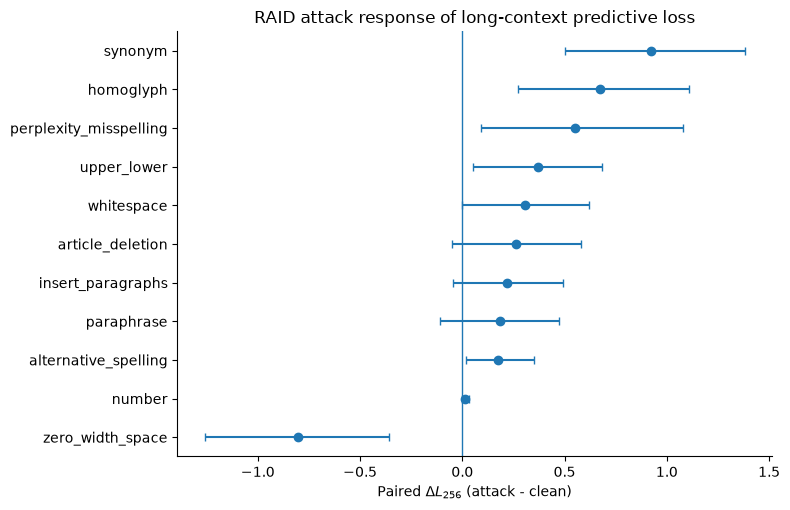

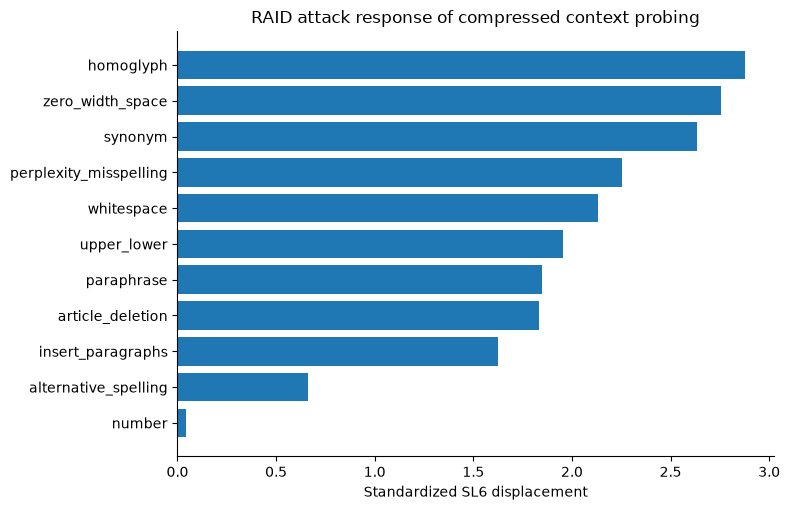

=== COMPLETE-PANEL RAID ATTACK RESPONSE ===
complete parents: 33
paired rows: 363


,attack,n,mean_delta,median_delta,ci95_lo,ci95_hi,paired_dz,normalized_sensitivity
47,synonym,33,0.923375,1.004177,0.501436,1.382435,0.714777,0.972099
65,zero_width_space,33,-0.805062,-0.629127,-1.260369,-0.358925,-0.599309,0.933879
17,homoglyph,33,0.675230,0.627187,0.273331,1.105912,0.548515,0.913919
41,perplexity_misspelling,33,0.548521,0.133706,0.089287,1.080077,0.368843,0.840205
59,whitespace,33,0.304090,0.290633,0.000382,0.621733,0.322857,0.649884
53,upper_lower,33,0.368202,0.240587,0.054039,0.684152,0.392604,0.603463
11,article_deletion,33,0.260684,0.128313,-0.049986,0.580716,0.277224,0.595180
35,paraphrase,33,0.183815,0.118166,-0.108465,0.475116,0.213569,0.553530
23,insert_paragraphs,33,0.219187,0.152325,-0.043822,0.490458,0.275971,0.525914
5,alternative_spelling,33,0.175162,0.000000,0.017266,0.351235,0.352321,0.233249


feature,L_128,L_16,L_256,L_32,L_64,L_8
attack,,,,,,
alternative_spelling,0.072800,0.047958,0.175162,0.014957,0.008632,0.137656
article_deletion,0.189699,0.012946,0.260684,0.126909,0.119934,-0.030951
homoglyph,0.926931,0.775346,0.675230,0.800919,0.928799,0.793018
insert_paragraphs,0.192766,0.191578,0.219187,0.198723,0.200171,0.312564
number,0.011705,0.012514,0.012660,0.017455,0.012108,0.016892
paraphrase,0.115349,0.095264,0.183815,-0.030239,0.105331,-0.030015
perplexity_misspelling,0.462668,0.487399,0.548521,0.427954,0.496359,0.524488
synonym,0.889243,0.706971,0.923375,0.795694,0.827758,0.873131
upper_lower,0.379881,0.582569,0.368202,0.483784,0.504695,0.652920


In [30]:
l256 = summary[summary["feature"].eq("L_256")].sort_values("mean_delta").reset_index(drop=True)

fig,ax = plt.subplots(figsize=(8,5.2))
y = np.arange(len(l256))
m = l256["mean_delta"].to_numpy()
lo = m-l256["ci95_lo"].to_numpy()
hi = l256["ci95_hi"].to_numpy()-m
ax.errorbar(m,y,xerr=np.vstack([lo,hi]),fmt="o",capsize=3)
ax.axvline(0,linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(l256["attack"])
ax.set_xlabel(r"Paired $\Delta L_{256}$ (attack - clean)")
ax.set_title("RAID attack response of long-context predictive loss")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"raid_machine_attack_delta_L256.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"raid_machine_attack_delta_L256.png",dpi=200,bbox_inches="tight")
plt.show()

g = sl6.sort_values("mean")
fig,ax = plt.subplots(figsize=(8,5.2))
y = np.arange(len(g))
ax.barh(y,g["mean"])
ax.set_yticks(y)
ax.set_yticklabels(g.index)
ax.set_xlabel("Standardized SL6 displacement")
ax.set_title("RAID attack response of compressed context probing")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"raid_machine_attack_sl6_displacement.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"raid_machine_attack_sl6_displacement.png",dpi=200,bbox_inches="tight")
plt.show()

print("=== COMPLETE-PANEL RAID ATTACK RESPONSE ===")
print("complete parents:",len(complete_parent_ids))
print("paired rows:",len(paired))

display(
    summary[summary["feature"].eq("L_256")]
    [["attack","n","mean_delta","median_delta","ci95_lo","ci95_hi","paired_dz","normalized_sensitivity"]]
    .sort_values("normalized_sensitivity",ascending=False)
)

display(
    summary.pivot(
        index="attack",
        columns="feature",
        values="mean_delta",
    )
)
